Images successfully loaded and converted to grayscale.


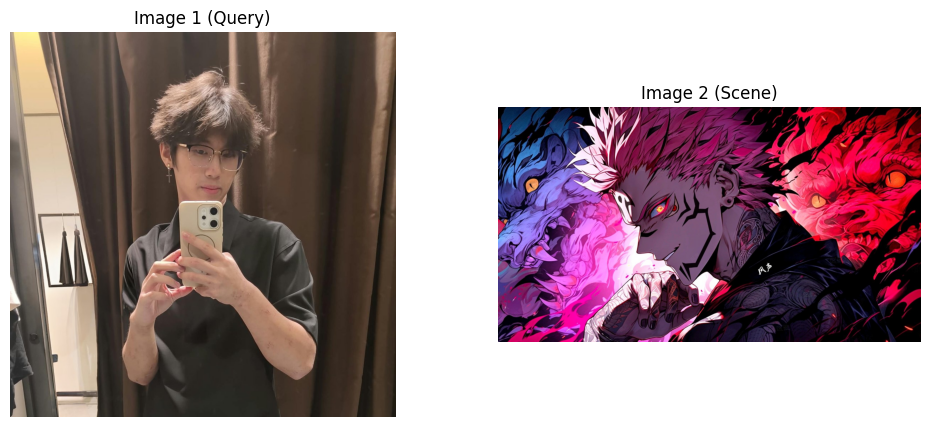

Keypoints detected in Image 1: 1000
Keypoints detected in Image 2: 1000


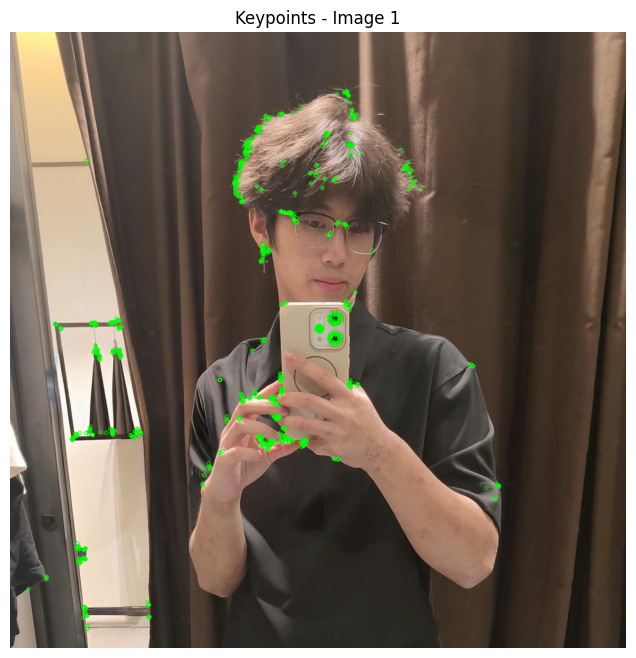

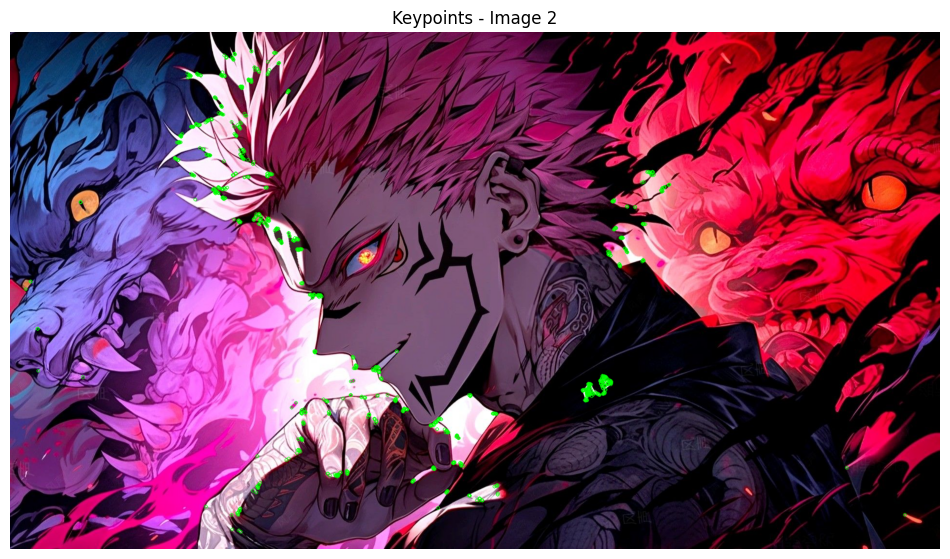

Total matches found: 266


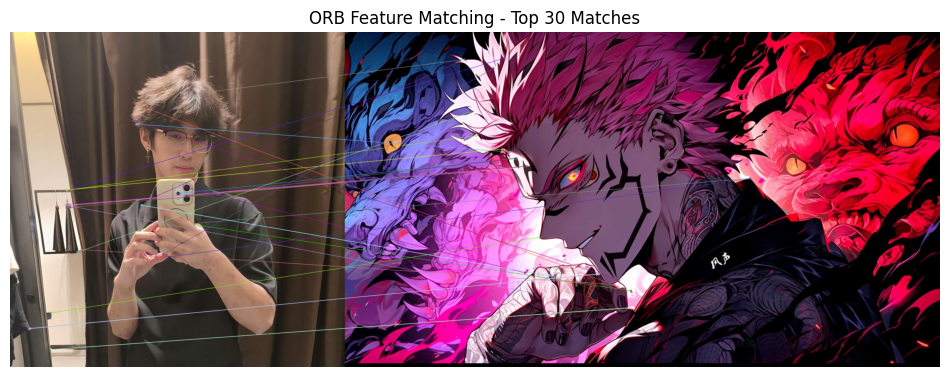

In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Helper function to display images properly in Jupyter/Colab
def show_img(title, img):
    plt.figure(figsize=(12, 8))
    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

# ==========================================
# Step 1: Load and Prepare Images
# ==========================================
img1 = cv2.imread('798152411_18115763803971352_1353216150347601758_n.jpg') # Query image
img2 = cv2.imread('65e6b562e2cea31b82f492fc9a58941e.jpg')                  # Train/Scene image

if img1 is None or img2 is None:
    raise FileNotFoundError("Could not load one or both images. Check your file paths.")

# Convert to grayscale (required for ORB feature detection)
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

print("Images successfully loaded and converted to grayscale.")

# Display original images side by side
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Image 1 (Query)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.title("Image 2 (Scene)")
plt.axis('off')
plt.show()

# ==========================================
# Step 2: ORB Feature Detection & Extraction
# ==========================================
orb = cv2.ORB_create(nfeatures=1000)

# Find keypoints and descriptors
kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

print(f"Keypoints detected in Image 1: {len(kp1)}")
print(f"Keypoints detected in Image 2: {len(kp2)}")

# Draw keypoints on both images
img1_kp = cv2.drawKeypoints(img1, kp1, None, color=(0, 255, 0), flags=0)
img2_kp = cv2.drawKeypoints(img2, kp2, None, color=(0, 255, 0), flags=0)

show_img("Keypoints - Image 1", img1_kp)
show_img("Keypoints - Image 2", img2_kp)

# ==========================================
# Step 3: Feature Matching (Brute-Force Matcher)
# ==========================================
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors and sort by distance (lower = better match)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Total matches found: {len(matches)}")

# Draw the top 30 best matches
result_img = cv2.drawMatches(
    img1, kp1, img2, kp2, matches[:30], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Save the final result image for submission
cv2.imwrite('final_result.jpg', result_img)

# Display the final matched result
show_img("ORB Feature Matching - Top 30 Matches", result_img)